# Agglomerative Hierarchical Clustering: baseline and tuned car segments
**Review 2 · Clustering · no target labels used in fitting**

Dataset: 4,009 used-car listings. Price is USD; `milage` contains miles, despite its spelling.
Numeric segmentation uses **car age, log price and log mileage**, standardized after training-only
median imputation. Brand, engine text, transmission, colour, accident and title fields do not define
distance; they remain available for post-fit interpretation. This avoids arbitrary weighting of
high-cardinality categories. Price is a clustering feature, not a supervised target.

Baseline: k=3 (Ward linkage for hierarchical clustering). Search: k=2..6; hierarchical also searches
Ward/complete/average linkage. Fit preprocessing on each training fold, assign validation rows,
and select by mean five-fold validation silhouette. K-Means uses native prediction. Hierarchical
uses an explicit nearest-training-centroid **proxy**, because the algorithm has no native predict.
This proxy evaluates deployable assignments, not a new hierarchical fit on validation cars.

A separate 20% holdout is never used to select k/linkage. Report intrinsic training partition metrics
and held-out assignment metrics separately. Silhouette is sampled to at most 2,000 rows with seed 42;
Davies–Bouldin and Calinski–Harabasz use all rows in each evaluated set.


In [1]:
from pathlib import Path
import sys, os, warnings, json
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if not (ROOT / 'src').exists():
    raise RuntimeError('Open this notebook inside the extracted project/notebooks folder.')
sys.path.insert(0, str(ROOT))
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=1)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
%matplotlib inline
sns.set_theme(style='whitegrid', palette='colorblind')
from src.clustering import *
raw, df, train, test = load_data()
display(raw.dtypes.to_frame('dtype').astype(str))
display(raw.isna().sum().to_frame('Missing raw values'))
print('Raw / cleaned / train / holdout:', len(raw), len(df), len(train), len(test))
print('Exact duplicates removed:', len(raw)-len(df))
display(train[['price_usd','mileage_miles','car_age']].describe())


Raw / cleaned / train / holdout: 4009 4009 3207 802
Exact duplicates removed: 0


,dtype
brand,object
model,object
model_year,int64
milage,object
fuel_type,object
engine,object
transmission,object
ext_col,object
int_col,object
accident,object


,Missing raw values
brand,0
model,0
model_year,0
milage,0
fuel_type,170
engine,0
transmission,0
ext_col,0
int_col,0
accident,113


,price_usd,mileage_miles,car_age
count,3207.0,3207.0,3207.000000
mean,43125.756782,64942.199563,10.442158
std,51204.51605,52433.516741,6.032533
min,2000.0,100.0,2.000000
25%,17050.0,23319.5,6.000000
50%,31300.0,53500.0,9.000000
75%,49999.0,93985.5,14.000000
max,749950.0,405000.0,52.000000


## Training EDA and preparation
Money and mileage strings are parsed to numbers; invalid values become missing. Log transforms reduce skew while retaining extreme cars. Missing values are learned from each training fold.

**Team task:** add observations and justify the chosen features after reviewing these plots.

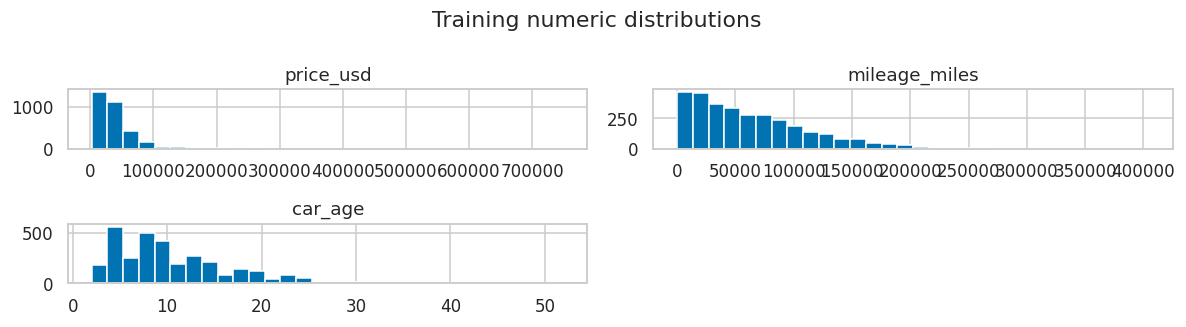

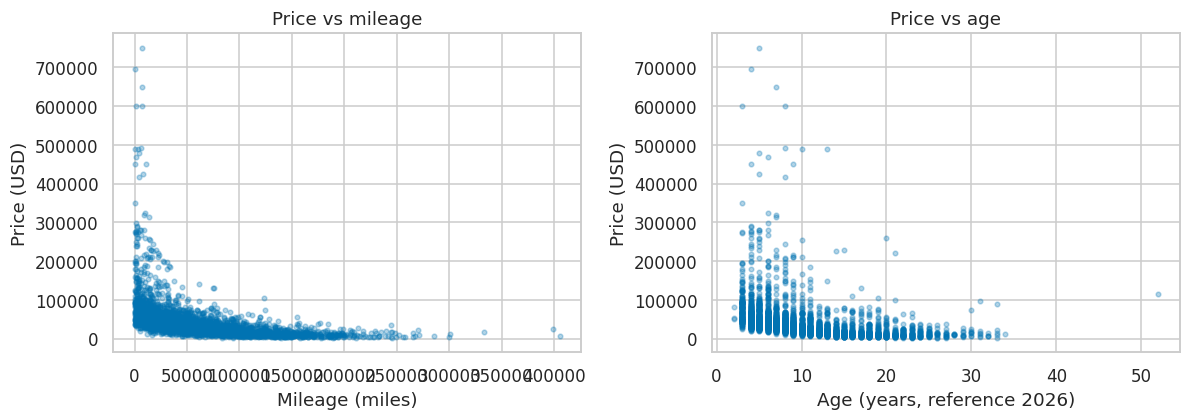

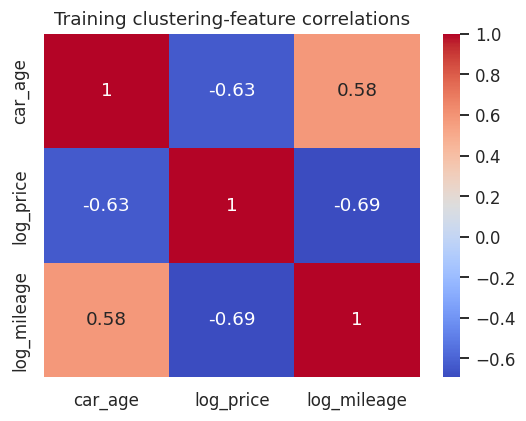

,IQR outliers retained
price_usd,191
mileage_miles,58
car_age,52


In [2]:
train[['price_usd','mileage_miles','car_age']].hist(bins=30,figsize=(11,3))
plt.suptitle('Training numeric distributions'); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(train.mileage_miles, train.price_usd, alpha=.3, s=9)
axes[0].set(xlabel='Mileage (miles)',ylabel='Price (USD)',title='Price vs mileage')
axes[1].scatter(train.car_age, train.price_usd, alpha=.3, s=9)
axes[1].set(xlabel='Age (years, reference 2026)',ylabel='Price (USD)',title='Price vs age')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(5,4))
sns.heatmap(ClusterFeatures().transform(train).corr(),annot=True,cmap='coolwarm',ax=ax)
ax.set_title('Training clustering-feature correlations'); plt.tight_layout(); plt.show()
q = train[['price_usd','mileage_miles','car_age']]
iqr=q.quantile(.75)-q.quantile(.25)
display(((q<q.quantile(.25)-1.5*iqr)|(q>q.quantile(.75)+1.5*iqr)).sum().to_frame('IQR outliers retained'))


## Five-fold parameter search
Candidates with collapsed validation clusters are rejected. Higher silhouette and Calinski–Harabasz are better; lower Davies–Bouldin is better. The metrics may disagree.

In [3]:
kind = 'agglomerative'
search_summary, fold_results, best = tune(kind, train)
display(search_summary.sort_values('CV_silhouette', ascending=False))
print('Chosen on training folds only:', best)
out = ROOT / 'results' / kind
out.mkdir(parents=True, exist_ok=True)
fold_results.to_csv(out / 'cv_fold_results.csv', index=False)


Chosen on training folds only: {'k': 2, 'linkage': 'ward'}


,k,linkage,CV_silhouette,CV_silhouette_std,CV_Davies_Bouldin,CV_Calinski_Harabasz,valid_folds,min_represented_clusters,eligible
0,2,average,0.443144,0.057472,0.616109,68.541974,3,1,False
2,2,ward,0.407265,0.013249,0.881820,570.715496,5,2,True
1,2,complete,0.399943,0.017229,0.875750,510.390396,5,2,True
4,3,complete,0.392341,0.015392,0.871280,483.397578,5,2,False
3,3,average,0.378347,0.031474,0.818288,186.720217,5,2,False
7,4,complete,0.369590,0.027328,0.860118,512.693895,5,3,False
5,3,ward,0.366295,0.026444,0.898613,582.174710,5,3,True
10,5,complete,0.343930,0.023696,0.941014,493.640420,5,4,False
9,5,average,0.338247,0.044007,0.820805,308.839939,5,4,False
8,4,ward,0.328765,0.019949,0.967116,545.849958,5,4,True


## Before/after comparison and held-out checks

In [4]:
comparison, fitted, prep, X, X_holdout, pca, profiles = fit_compare(kind, train, test, search_summary, best)
display(comparison.round(4))
cols=['Silhouette','Davies_Bouldin','Calinski_Harabasz','CV_silhouette','Holdout_Silhouette']
display((comparison.loc[1,cols]-comparison.loc[0,cols]).to_frame('After minus before'))
display(profiles)


,Model,Stage,k,linkage,Silhouette,Davies_Bouldin,Calinski_Harabasz,CV_silhouette,CV_silhouette_std,Holdout_Silhouette,Holdout_Davies_Bouldin,Holdout_Calinski_Harabasz
0,Agglomerative,Before tuning,3,ward,0.3595,0.8799,2622.7525,0.3663,0.0264,0.3800,0.9105,708.7527
1,Agglomerative,After tuning,2,ward,0.3951,0.8755,2161.4716,0.4073,0.0132,0.4243,0.8506,680.4945


,After minus before
Silhouette,0.035584
Davies_Bouldin,-0.004325
Calinski_Harabasz,-461.280936
CV_silhouette,0.04097
Holdout_Silhouette,0.044248


,cars,median_price_usd,median_mileage_miles,median_age
cluster,,,,
0,2427,38436.0,39192.0,7.0
1,780,11500.0,112000.0,18.0


## Required visualizations
Both fits use the same PCA axes. PCA and t-SNE are visualizations only, not inputs to model fitting. Cluster numbers are arbitrary, not quality rankings. The elbow/dendrogram is a diagnostic; numerical selection comes from the stated CV rule.

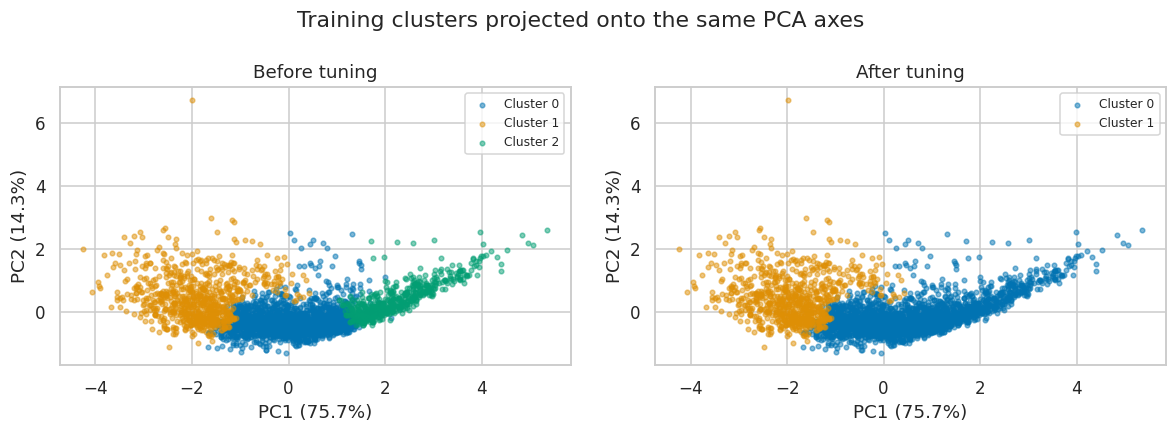

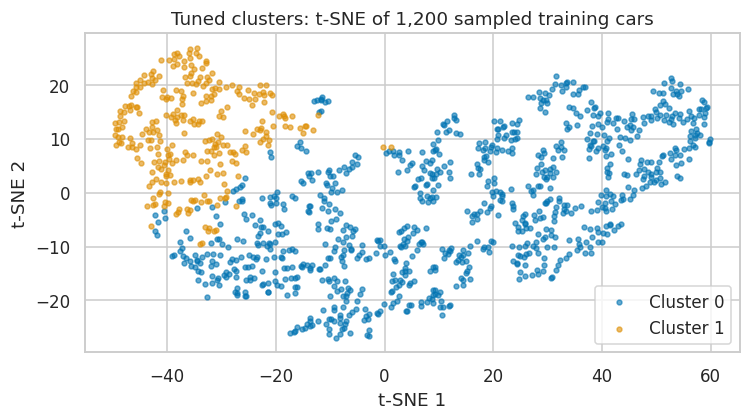

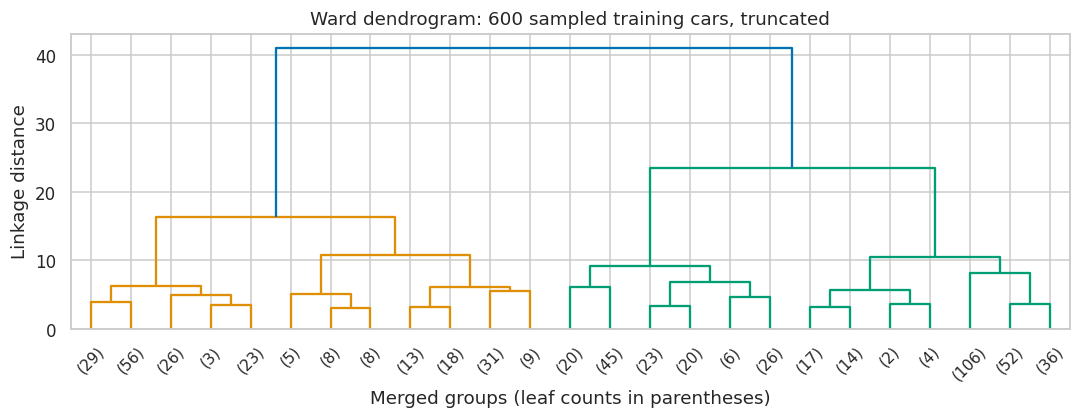

,Diesel,E85 Flex Fuel,Gasoline,Hybrid,Plug-In Hybrid,not supported,–
cluster,,,,,,,
0,0.034,0.033,0.851,0.063,0.013,0.001,0.005
1,0.021,0.053,0.878,0.018,0.001,0.000,0.030


In [5]:
plot_clusters(kind, fitted, X, pca)
display(pd.read_csv(out / 'fuel_type_profile.csv', index_col=0).round(3))


## Team interpretation
Write your own conclusions: which cluster contains older/high-mileage cars, how price differs,
whether the elbow or dendrogram supports the selected k, and whether all metrics agree.
Discuss limitations of three numeric features, centroid-proxy assignment (hierarchical only),
sampled silhouette and t-SNE. Do not call these clusters known ground-truth categories.

Source: [scikit-learn clustering guide](https://scikit-learn.org/stable/modules/clustering.html).
